# 02. Tools and MCP

## Problem

A malformed search must fail before retrieval, while a backend timeout must remain distinct from a successful empty result. The same search is also exposed through MCP.

## Learning objectives

Design tool schemas, preserve call IDs, classify errors, bound reads and pagination, execute local MCP, and configure authenticated remote transport.

Run top to bottom in a fresh kernel. The lab uses actual model calls, tools and temporary local storage. Configure the services before execution. Every plotted value declares its measurement kind.

In [1]:
import os
from pathlib import Path
from tempfile import TemporaryDirectory
from IPython.display import display
ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents]
            if (path / "pyproject.toml").exists())
os.chdir(ROOT)
scratch = TemporaryDirectory(prefix="northstar-course-")
os.environ["MPLCONFIGDIR"] = str(Path(scratch.name) / "matplotlib")
os.environ["LANGSMITH_TRACING"] = "false"
os.environ["LANGCHAIN_TRACING_V2"] = "false"
import matplotlib
get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
from deep_agent_lab.settings import Settings
from deep_agent_lab.courseware import diagram, bars
settings = Settings( deep_lab_mode="live", langfuse_enabled=False,
                    deep_lab_state_dir=Path(scratch.name) / "state")
assert settings.deep_lab_mode == "live" and not settings.langfuse_enabled

## Concept explanation

## Tool descriptions influence behavior

A poorly designed tool might look like this:

The model cannot reliably infer what source it searches, how many results are returned, or what a failure looks like.

A better design uses explicit arguments and an unambiguous description:

Now the model sees exactly which search modes are valid.

The application can reject invalid requests before consuming backend resources.

## Three outcomes that must remain distinct

**Successful search with zero matches**

The search ran correctly, but no evidence was found. The agent may reformulate its query or report an evidence gap.

**Invalid request**

The model supplied `top_k=100000`, which violates the contract. Reject it without executing retrieval.

**Transient infrastructure failure**

OpenSearch timed out. The absence of results has not been established. Retry within a budget or report retrieval unavailable.

Treating a timeout as "no results" creates a dangerous failure: the agent may confidently claim that a policy does not exist when the search backend was unavailable.

## MCP: Model Context Protocol

MCP standardizes communication between an application and external services exposing tools, resources, or prompts.

It separates three concepts:

- **Host:** The application running the assistant.
- **Client:** The protocol component connecting to a server.
- **Server:** The component exposing capabilities.

The repository's MCP lab already demonstrates a local `FastMCP` server over stdio.

For local development, stdio is often sufficient.

For independently hosted services, an HTTP transport may be appropriate, but it introduces authentication, authorization, server identity, networking, and protocol-version concerns.

**Important:** MCP is a protocol, not a security boundary by itself.

Tool outputs remain untrusted data. A remote server's description cannot authorize actions, and a retrieved document cannot grant itself permission to invoke a write.

## Mental model

Read the following diagram as an application boundary: the model proposes actions while the runtime performs validated operations. The figure renders through Matplotlib in the notebook output.

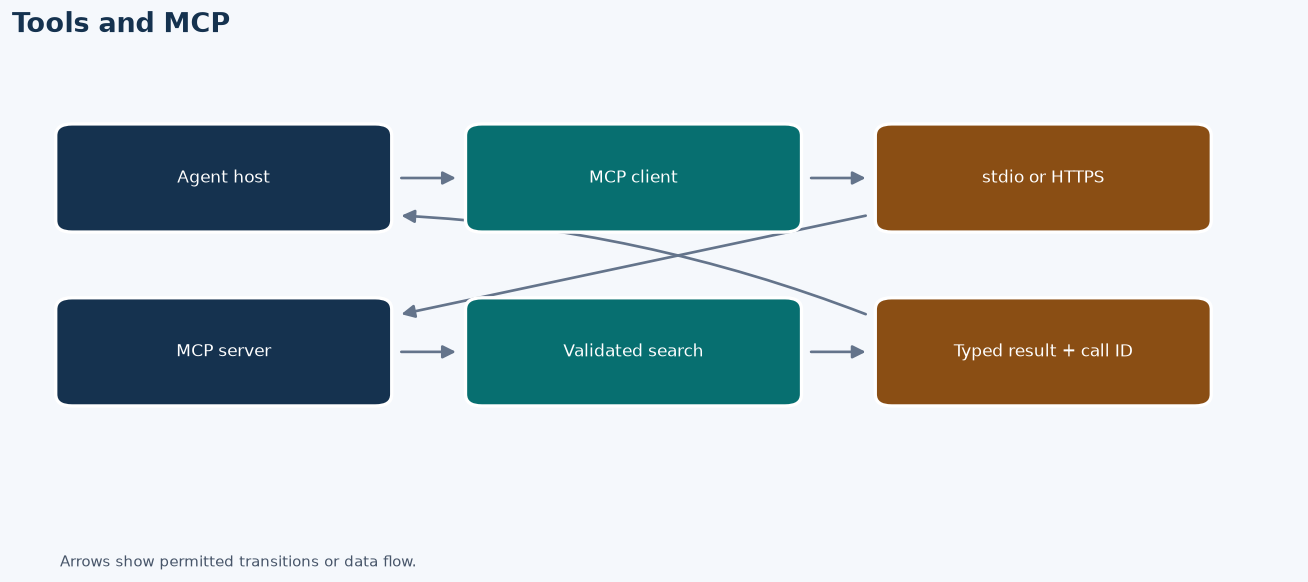

In [2]:
display(diagram('Tools and MCP', ['Agent host', 'MCP client', 'stdio or HTTPS', 'MCP server', 'Validated search', 'Typed result + call ID'], [(0, 1), (1, 2), (2, 3), (3, 4), (4, 5), (5, 0)]))
plt.close('all')

## Implementation from scratch

Build the smallest inspectable mechanism before connecting it to the full application. The code below exposes state and checks the invariant that motivates this module.

In [3]:
import asyncio, json
from deep_agent_lab.foundations import SearchArgs
from deep_agent_lab.tooling import search_read
from deep_agent_lab.knowledge import local_search
print(json.dumps(SearchArgs.model_json_schema(), indent=2))
backend_calls = []
async def actual_search(request: SearchArgs):
    backend_calls.append(request.model_dump())
    rows = await asyncio.to_thread(local_search, ROOT / "data/sample", request.query, request.top_k)
    return [row.model_dump() for row in rows]
success = await search_read(actual_search, {"query":"production restore"}, call_id="read-1")
empty = await search_read(actual_search, {"query":"ZEPHYR-99"}, call_id="read-2")
assert success.status == "success" and empty.status == "success" and empty.hits == []
print(success.model_dump(), empty.model_dump())


{
  "additionalProperties": false,
  "properties": {
    "query": {
      "maxLength": 4000,
      "minLength": 1,
      "pattern": "\\S",
      "title": "Query",
      "type": "string"
    },
    "top_k": {
      "default": 3,
      "maximum": 5,
      "minimum": 1,
      "title": "Top K",
      "type": "integer"
    }
  },
  "required": [
    "query"
  ],
  "title": "SearchArgs",
  "type": "object"
}
{'call_id': 'read-1', 'status': 'success', 'hits': [{'id': 'aa56ac1a81669a78a15eff57b39165d2502dffea1966e136363a077ca954d556', 'title': 'backup-policy', 'source': 'file:///C:/Users/imrah/Documents/deepagents/data/sample/backup-policy.md', 'position': 0, 'excerpt': '# Northstar database backup policy\n\nThis is fictional sample knowledge for the RAG Lab.\n\nCourse source alias: BKP-7, revision 4.\n\nProduction PostgreSQL databases receive a full backup every day at 02:00 UTC. Transaction logs are archived continuously to support point-in-time recovery. Daily backups are retained for 30 da

## Framework implementation

The following cell executes the existing Deep Agents/LangGraph application or its actual integration boundary. Inspect the actual service configuration and returned observations in each cell.

In [4]:
from deep_agent_lab.labs import mcp_lab
mcp_result = await mcp_lab()
print(mcp_result)
assert "search" in mcp_result["tools"]


{'tools': ['search'], 'results': ['{\n  "id": "eb721ead272932f268eda808804085cce511a3605719cc51cd3ccdb0f1d2ff5b",\n  "title": "backup-policy",\n  "source": "file:///C:/Users/imrah/Documents/deepagents/data/sample/backup-policy.md",\n  "position": 0,\n  "excerpt": "# Northstar database backup policy\\n\\nThis is fictional sample knowledge for the RAG Lab.\\n\\nProduction PostgreSQL databases receive a full backup every day at 02:00 UTC. Transaction logs are archived continuously to support point-in-time recovery. Daily backups are retained for 30 days and monthly backups are retained for 12 months.\\n\\nTo restore accidentally deleted customer records, open a restore request with the database operations team. The database operations lead must approve a production restore. Restore into an isolated database first, verify the requested records, and agree on the recovery plan before changing production.\\n\\nThe recovery point objective is 15 minutes. The recovery time objective is four hou

## Code walkthrough

`asyncio.timeout` bounds an async transport attempt; it cannot forcibly kill arbitrary blocking code. Cancellation propagates rather than becoming a retry. `ToolOutcome` keeps success-with-zero-hits distinct from unavailable retrieval. The MCP lab launches the repository's actual stdio server, discovers its schema, and calls it through ClientSession. Protocol request IDs and the agent's tool-call IDs serve different layers. `remote_mcp_search` uses the installed SDK's real Streamable HTTP client with redirects disabled; OAuth token acquisition belongs to the trusted identity layer. Tool descriptions and returned content grant no permissions.

## Interactive experiments

Vary attempt count, excerpt size and pagination budget. Treat a repeated cursor as a protocol failure rather than looping forever.

In [5]:
before = len(backend_calls)
invalid = await search_read(actual_search, {"query":"restore","top_k":100000}, call_id="bad-1")
assert invalid.status == "invalid_request" and len(backend_calls) == before
print(invalid.model_dump())


{'call_id': 'bad-1', 'status': 'invalid_request', 'hits': [], 'error_code': 'schema', 'attempts': 0}


## Failure experiment

Deliberately violate a contract or remove a required condition. A caught, asserted failure is an expected result; an uncaught error means this notebook has not passed.

In [6]:
# Apply a real deadline to an actual read. Cancellation cannot kill a synchronous worker.
deadline_result = await search_read(actual_search, {"query":"restore"},
                                  call_id="deadline-1", timeout=0.000001, attempts=1)
print("Observed deadline result:", deadline_result.model_dump())
assert deadline_result.status in {"success", "transient_error"}


Observed deadline result: {'call_id': 'deadline-1', 'status': 'transient_error', 'hits': [], 'error_code': 'unavailable', 'attempts': 1}


## Verification

These assertions inspect actual state produced above. They establish the stated contracts within this lab's scope.

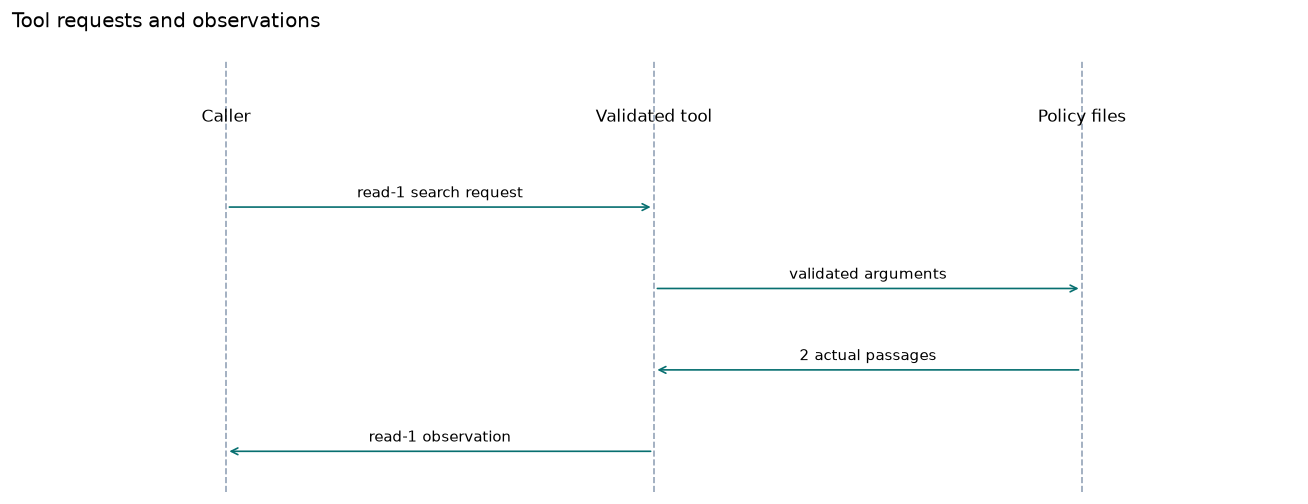

In [7]:
assert success.call_id == "read-1" and success.attempts == 1
assert invalid.attempts == 0 and not invalid.hits

from deep_agent_lab.courseware import tool_sequence
display(tool_sequence(["Caller","Validated tool","Policy files"], [
    (0,1,success.call_id+" search request"),(1,2,"validated arguments"),
    (2,1,str(len(success.hits))+" actual passages"),(1,0,success.call_id+" observation")]))
plt.close("all")


## Exercise

Collect a two-page MCP tool listing while allowing no more than two pages. Then simulate a server returning the same cursor forever and reject it.

Try your implementation before running the complete reference solution in the next cell.

### Reference solution

Compare the implementation and assertions with your attempt.

In [8]:
from deep_agent_lab.tooling import remote_headers
try:
    remote_headers("http://untrusted.example/mcp", "example-token", frozenset())
except PermissionError:
    print("Untrusted origin rejected before network access")


Untrusted origin rejected before network access


## Trade-offs and further reading

MCP helps interoperability and process separation. A normal Python function is simpler for an internal tool in the same process. HTTP authentication must validate issuer, audience, expiry and scopes at the server; a bearer header helper does not implement an OAuth server. Remote MCP is optional and requires your own endpoint.

[Primary source 1](https://modelcontextprotocol.io/specification/2025-11-25/basic/transports) Â· [Primary source 2](https://modelcontextprotocol.io/specification/2025-11-25/basic/authorization)

In [9]:
plt.close('all')
scratch.cleanup()
print('All executed module assertions passed.')

All executed module assertions passed.
